<a href="https://colab.research.google.com/github/keyaa21/Machine-Learning-Using-Python/blob/main/Ridge_Lasso_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# 1. Data Loading and Exploration
# ==========================================
df = pd.read_csv("CarPrice_Assignment.csv")
print("--- First 5 Rows ---")
print(df.head())

print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

print("\n--- Data Types ---")
print(df.dtypes)

# Explicitly identify categorical vs. numerical columns
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nCategorical Columns ({len(cat_cols)}): {cat_cols}")
print(f"Numerical Columns ({len(num_cols)}): {num_cols}")

print("\n--- Missing Values ---")
print(df.isnull().sum())
df = df.dropna()  # Handle missing values if any

print("\n--- Basic Statistical Details ---")
print(df.describe())

--- First 5 Rows ---
   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  convertible        rwd          front       88.6  ...         130   
1  convertible        rwd          front       88.6  ...         130   
2    hatchback        rwd          front       94.5  ...         152   
3        sedan        fwd          front       99.8  ...         109   
4        sedan        4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horsepowe

In [ ]:
# 2. Feature Selection & Normalization
# ==========================================
features = ["enginesize", "horsepower", "carwidth", "curbweight", "highwaympg"]
target = "price"

X = df[features]
y = df[target]

# Normalize features (Crucial for Ridge & Lasso Regularization)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# 3. Data Splitting (80% Train, 20% Test)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")


Training set shape: (164, 5)
Testing set shape: (41, 5)


In [ ]:
# 4. Model Implementation and Training
# ==========================================
# a. Multiple Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# b. Ridge Regression (alpha = 1.0)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

# c. Lasso Regression (alpha = 1.0)
lasso = Lasso(alpha=1.0)
lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

# Display Intercepts and Coefficients
coef_comparison = pd.DataFrame(
    {
        "Feature": features,
        "Linear_Coef": lr.coef_,
        "Ridge_Coef (alpha=1.0)": ridge.coef_,
        "Lasso_Coef (alpha=1.0)": lasso.coef_,
    }
)
print("\n--- Model Coefficients ---")
print(coef_comparison.to_string(index=False))

# Display Comparison Table
results_df = pd.DataFrame(
    {
        "Model": [
            "Multiple Linear Regression",
            "Ridge Regression (alpha=1.0)",
            "Lasso Regression (alpha=1.0)",
        ],
        "Intercept": [lr.intercept_, ridge.intercept_, lasso.intercept_],
        "RMSE": [rmse_lr, rmse_ridge, rmse_lasso],
        "R2 Score": [r2_lr, r2_ridge, r2_lasso],
    }
)

print("\n========================================================")
print("              MODEL PERFORMANCE COMPARISON              ")
print("========================================================")
print(results_df.to_string(index=False))


--- Model Coefficients ---
   Feature  Linear_Coef  Ridge_Coef (alpha=1.0)  Lasso_Coef (alpha=1.0)
enginesize  3332.049613             3274.680605             3331.600677
horsepower  1984.207502             1988.839143             1984.113559
  carwidth  1348.439995             1336.143506             1348.534368
curbweight   876.489695              920.545021              876.287267
highwaympg  -277.752807             -283.723804             -277.100489

              MODEL PERFORMANCE COMPARISON              
                       Model    Intercept        RMSE  R2 Score
  Multiple Linear Regression 13215.580343 3816.532856  0.815490
Ridge Regression (alpha=1.0) 13214.687323 3821.918671  0.814969
Lasso Regression (alpha=1.0) 13215.593006 3816.508467  0.815493


In [ ]:
# 5. Comparison & Alpha Experimentation
# ==========================================
best_idx = results_df["RMSE"].idxmin()
print(
    f"\n6a. Best Performing Model: {results_df.loc[best_idx, 'Model']} "
    f"(Lowest RMSE: {results_df.loc[best_idx, 'RMSE']:,.2f}, Highest R2: {results_df.loc[best_idx, 'R2 Score']:.4f})"
)

alphas = [0.1, 1.0, 5.0, 10.0, 100.0]
print("\n--- Ridge & Lasso Alpha Sensitivity Analysis ---")
for a in alphas:
    r_m = Ridge(alpha=a).fit(X_train, y_train)
    r_pred = r_m.predict(X_test)

    l_m = Lasso(alpha=a).fit(X_train, y_train)
    l_pred = l_m.predict(X_test)

    print(
        f"Alpha: {a:5.1f} | "
        f"Ridge RMSE: {np.sqrt(mean_squared_error(y_test, r_pred)):,.2f}, R2: {r2_score(y_test, r_pred):.4f} | "
        f"Lasso RMSE: {np.sqrt(mean_squared_error(y_test, l_pred)):,.2f}, R2: {r2_score(y_test, l_pred):.4f}"
    )

print(
    "\n6b. Alpha Analysis Conclusion: Increasing alpha increases the regularization penalty, "
    "shrinking coefficients toward zero. Moderate alpha values help stabilize the model, "
    "while excessively large alpha values (like 100) lead to underfitting."
)


6a. Best Performing Model: Lasso Regression (alpha=1.0) (Lowest RMSE: 3,816.51, Highest R2: 0.8155)

--- Ridge & Lasso Alpha Sensitivity Analysis ---
Alpha:   0.1 | Ridge RMSE: 3,817.05, R2: 0.8154 | Lasso RMSE: 3,816.53, R2: 0.8155
Alpha:   1.0 | Ridge RMSE: 3,821.92, R2: 0.8150 | Lasso RMSE: 3,816.51, R2: 0.8155
Alpha:   5.0 | Ridge RMSE: 3,845.88, R2: 0.8126 | Lasso RMSE: 3,816.28, R2: 0.8155
Alpha:  10.0 | Ridge RMSE: 3,877.18, R2: 0.8096 | Lasso RMSE: 3,815.98, R2: 0.8155
Alpha: 100.0 | Ridge RMSE: 4,269.08, R2: 0.7691 | Lasso RMSE: 3,813.37, R2: 0.8158

6b. Alpha Analysis Conclusion: Increasing alpha increases the regularization penalty, shrinking coefficients toward zero. Moderate alpha values help stabilize the model, while excessively large alpha values (like 100) lead to underfitting.


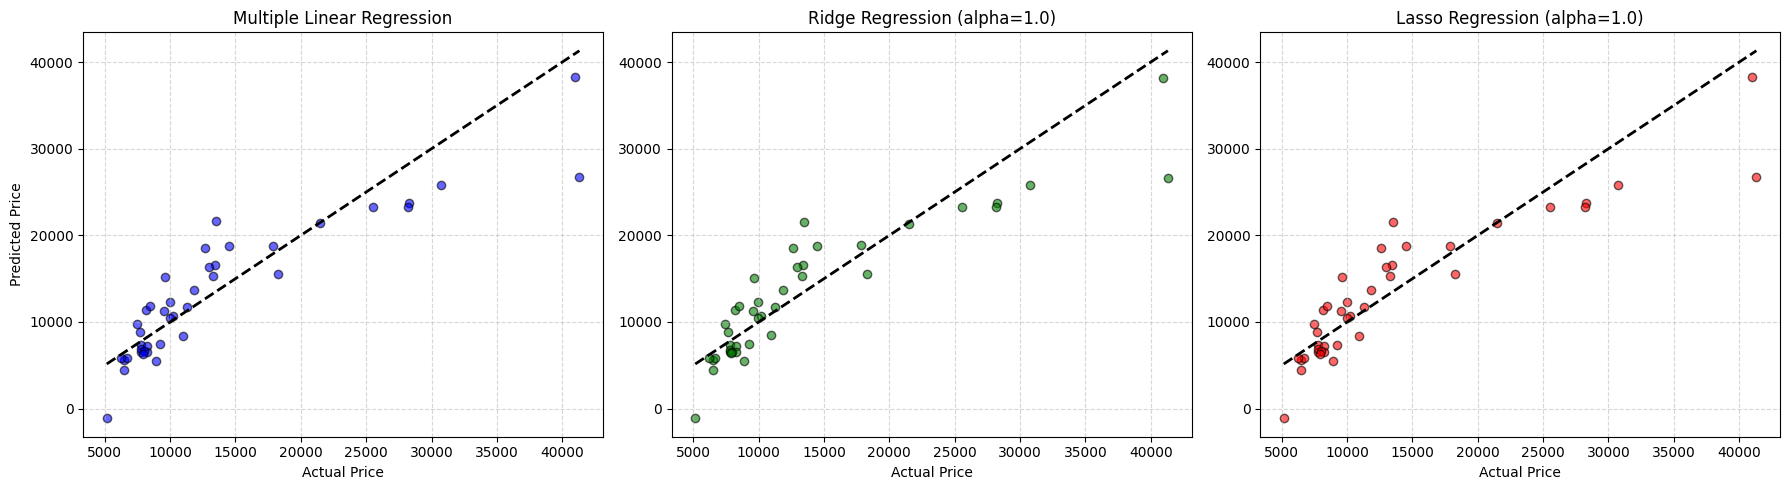

In [ ]:
# 6. Actual vs. Predicted Price Visualizations
# ==========================================
plt.figure(figsize=(18, 5))

# Plot 1: Multiple Linear Regression
plt.subplot(1, 3, 1)
plt.scatter(y_test, y_pred_lr, alpha=0.6, color="blue", edgecolors="k")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "k--",
    lw=2,
)
plt.title("Multiple Linear Regression")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.grid(True, linestyle="--", alpha=0.5)

# Plot 2: Ridge Regression
plt.subplot(1, 3, 2)
plt.scatter(y_test, y_pred_ridge, alpha=0.6, color="green", edgecolors="k")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "k--",
    lw=2,
)
plt.title("Ridge Regression (alpha=1.0)")
plt.xlabel("Actual Price")
plt.grid(True, linestyle="--", alpha=0.5)

# Plot 3: Lasso Regression
plt.subplot(1, 3, 3)
plt.scatter(y_test, y_pred_lasso, alpha=0.6, color="red", edgecolors="k")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "k--",
    lw=2,
)
plt.title("Lasso Regression (alpha=1.0)")
plt.xlabel("Actual Price")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()